# 07 · A Neural Network Reference Model (MLP)

**The question:** How well does a simple neural network do on our data, compared with the best baseline (LightGBM)?

| | |
|---|---|
| **Input** | The **scaled** inputs of the two feature sets from Notebook 05 (`original42`, `total_and_byte44`) |
| **What we do** | Train a small neural network (an MLP) three times per feature set with different random seeds, and compare it with LightGBM from Notebook 06 |
| **Output** | 6 trained MLPs, their predictions and scores, and a clear reference point for the deep-learning models that follow |

### Why this notebook?

The project's main model will be a **deep-learning architecture** (Conv1D, attention and so on, inspired by the reference paper).
Before building it we need to know what a **plain neural network** can do. Later, if the complex model scores higher, we can tell whether
the gain comes from its special parts (convolution, attention) or just from being a neural network.

**Project path:** 01 Data → 02 Fair splits → 03 Preprocessing → 04 Feature engineering → 05 Feature selection → 06 Baselines → **07 Neural reference** → 08 Main model

## 1. Setup and load the inputs

Neural networks need the **scaled** inputs (log + robust scaling from Notebook 03), not the raw tree inputs.

In [1]:
import sys
import time
import warnings
from pathlib import Path
sys.path.insert(0, str(next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'src').is_dir())))

import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import sparse
from IPython.display import display
from sklearn.exceptions import ConvergenceWarning
from sklearn.metrics import (accuracy_score, average_precision_score, confusion_matrix, f1_score)
from sklearn.neural_network import MLPClassifier
from threadpoolctl import threadpool_limits

from src.notebook_helpers import (ROOT, TRAIN_CSV, RAW_SHA256, CLASSES, DATA, MODELS,
                                  sha256, save_table, save_figure, save_json, read_json, setup_style, write_leaderboard)
setup_style()
warnings.filterwarnings('ignore', category=ConvergenceWarning)   # we stop at exactly 30 epochs on purpose (section 3)
assert sha256(TRAIN_CSV) == RAW_SHA256['train']

SETS = ['original42', 'total_and_byte44']
NORMAL, WORMS = CLASSES.index('Normal'), CLASSES.index('Worms')
X = {(s, r): sparse.load_npz(DATA / f'05_{s}_scaled_{r}.npz') for s in SETS for r in ['train', 'model_selection']}
targets = {r: pd.read_csv(DATA / f'03_targets_{r}.csv') for r in ['train', 'model_selection']}
y_train = pd.Categorical(targets['train'].attack_cat, categories=CLASSES).codes
y_eval = pd.Categorical(targets['model_selection'].attack_cat, categories=CLASSES).codes

display(pd.DataFrame({s: [X[(s, 'train')].shape, X[(s, 'model_selection')].shape] for s in SETS}, index=['train', 'model_selection']))

,original42,total_and_byte44
train,"(140273, 193)","(140273, 195)"
model_selection,"(17534, 193)","(17534, 195)"


## 2. How an MLP works

An **MLP (multi-layer perceptron)** is the simplest kind of neural network. Ours looks like this:

| Step | What happens |
|---|---|
| **Input** | One flow = 193 (or 195) numbers |
| **Hidden layer 1** | 128 "neurons". Each one computes a weighted sum of all inputs and keeps it only if positive (**ReLU**) |
| **Hidden layer 2** | 64 neurons do the same with the outputs of layer 1 |
| **Output** | 10 scores, one per class, turned into 10 probabilities that add up to 1 (**softmax**) |
| **Prediction** | The class with the highest probability. Anything except Normal counts as "Attack" |

During training the network adjusts its weights so the probability of the correct class goes up (it minimises **cross-entropy loss**).

Here is the same calculation by hand with a toy network: 3 inputs, 2 hidden neurons, 3 classes.

In [2]:
x = np.array([0.5, -1.0, 2.0])                       # one flow with 3 (scaled) inputs
W1 = np.array([[0.2, -0.5], [0.4, 0.1], [0.3, 0.6]])  # weights input -> hidden
W2 = np.array([[1.0, -0.5, 0.2], [0.3, 0.8, -0.4]])   # weights hidden -> output

hidden = np.maximum(0, x @ W1)                        # weighted sums, then ReLU
scores = hidden @ W2                                  # one score per class
probabilities = np.exp(scores) / np.exp(scores).sum() # softmax

print('hidden values :', hidden.round(3))
print('class scores  :', scores.round(3))
print('probabilities :', probabilities.round(3), '-> predicted class', probabilities.argmax())

hidden values : [0.3  0.85]
class scores  : [ 0.555  0.53  -0.28 ]
probabilities : [0.415 0.405 0.18 ] -> predicted class 0


A real MLP does exactly this, only with many more numbers. Training finds good values for `W1`, `W2`, and so on.

## 3. The settings, and how they were chosen

| Setting | Value | In plain words |
|---|---|---|
| Hidden layers | 128 and 64 neurons | network size |
| `alpha` (L2 penalty) | 0.01 | discourages very large weights, which reduces overfitting |
| Optimizer | Adam, learning rate 0.001 | how the weights are updated |
| Batch size | 512 | rows used per update step |
| Epochs | exactly **30** | passes over all training rows |
| Seeds | 42, 43, 44 | three runs with different random starts |

**How they were chosen:** in the earlier project version two candidate sizes were tested with **grouped folds inside the `train` rows only**
(like Notebook 05, identical rows kept together). The larger network won. `model_selection` rows were not used for this choice.

In [3]:
search = pd.read_csv(ROOT / 'results/tables/neural_reference_v1/07_search_summary.csv')
search.insert(1, 'network', ['64 / 32 neurons, alpha 0.0001', '128 / 64 neurons, alpha 0.01'])
display(search[['network', 'mean_macro_f1', 'min_macro_f1', 'max_macro_f1']].rename(columns=lambda c: c.replace('_', ' ')))

,network,mean macro f1,min macro f1,max macro f1
0,"64 / 32 neurons, alpha 0.0001",0.5200,0.5011,0.5313
1,"128 / 64 neurons, alpha 0.01",0.5402,0.5160,0.5585


**Limitation to keep in mind:** only two settings and a fixed 30 epochs were tried. This is a **reasonable reference, not a fully optimised network**.
We do not add epochs or try new settings now, because choosing them after seeing `model_selection` scores would make the comparison unfair.

## 4. Train the six networks

Two feature sets × three seeds. Each run takes about two minutes on the CPU. We limit math libraries to 2 threads so the results are exactly reproducible.

In [4]:
def make_mlp(seed):
    return MLPClassifier(hidden_layer_sizes=(128, 64), activation='relu', solver='adam', alpha=0.01,
                         batch_size=512, learning_rate_init=0.001, max_iter=30, shuffle=True, random_state=seed,
                         tol=0.0, early_stopping=False, n_iter_no_change=31)   # never stop before 30 epochs


fitted, probabilities, losses, minutes = {}, {}, {}, {}
for set_name in SETS:
    for seed in [42, 43, 44]:
        model = make_mlp(seed)
        start = time.time()
        with threadpool_limits(limits=2):
            model.fit(X[(set_name, 'train')], y_train)
            proba = model.predict_proba(X[(set_name, 'model_selection')])
        assert model.n_iter_ == 30 and np.isfinite(model.loss_curve_).all()
        fitted[(set_name, seed)], probabilities[(set_name, seed)], losses[(set_name, seed)] = model, proba, model.loss_curve_
        minutes[(set_name, seed)] = (time.time() - start) / 60
        print(f'{set_name:17s} seed {seed}: macro F1 = {f1_score(y_eval, proba.argmax(1), average="macro", labels=range(10)):.4f}'
              f'  ({time.time() - start:.0f} s)')

original42        seed 42: macro F1 = 0.5187  (27 s)


original42        seed 43: macro F1 = 0.5272  (27 s)


original42        seed 44: macro F1 = 0.5134  (27 s)


total_and_byte44  seed 42: macro F1 = 0.5360  (28 s)


total_and_byte44  seed 43: macro F1 = 0.5152  (28 s)


total_and_byte44  seed 44: macro F1 = 0.5213  (28 s)


### Did the training behave well?

The training loss should fall smoothly. It is measured on training rows, so a falling loss shows the network is learning,
not that it will do well on new rows.

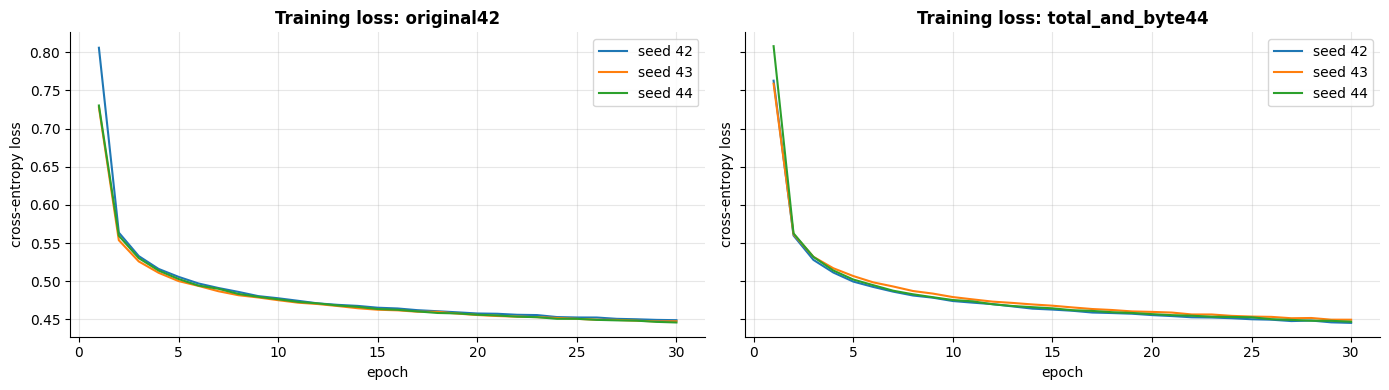

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4), sharey=True)
for ax, set_name in zip(axes, SETS):
    for seed in [42, 43, 44]:
        ax.plot(range(1, 31), losses[(set_name, seed)], label=f'seed {seed}')
    ax.set(title=f'Training loss: {set_name}', xlabel='epoch', ylabel='cross-entropy loss'); ax.legend()
plt.tight_layout(); save_figure(fig, '07_training_loss'); plt.show()

**What we see:** The loss drops quickly in the first few epochs and then flattens; the three seeds behave almost identically.
It is still falling slowly at epoch 30, so a longer run might help a little. That would be a separate, planned experiment.

## 5. Scores

We use exactly the same scoring as Notebook 06.

In [6]:
def score(y_true, proba):
    pred = proba.argmax(axis=1)
    attack_true, attack_pred = y_true != NORMAL, pred != NORMAL
    fp = int((~attack_true & attack_pred).sum()); tn = int((~attack_true & ~attack_pred).sum())
    tp = int((attack_true & attack_pred).sum()); fn = int((attack_true & ~attack_pred).sum())
    return {'macro F1': f1_score(y_true, pred, average='macro', labels=range(10), zero_division=0),
            'accuracy': accuracy_score(y_true, pred),
            'attack recall': tp / (tp + fn), 'false-positive rate': fp / (fp + tn),
            'attack avg precision': average_precision_score(attack_true, 1 - proba[:, NORMAL]),
            'Worms correct (of 13)': int(((y_true == WORMS) & (pred == WORMS)).sum())}


runs = pd.DataFrame([{'feature set': s, 'seed': seed, **score(y_eval, probabilities[(s, seed)])} for s in SETS for seed in [42, 43, 44]])
save_table(runs, '07_mlp_runs')
display(runs)

summary = runs.groupby('feature set')['macro F1'].agg(['mean', 'std', 'min', 'max']).rename(columns=lambda c: f'macro F1 {c}')
display(summary)
n_parameters = sum(w.size for w in fitted[('total_and_byte44', 42)].coefs_ + fitted[('total_and_byte44', 42)].intercepts_)
print(f'Trainable parameters (total_and_byte44 network): {n_parameters:,}')

,feature set,seed,macro F1,accuracy,attack recall,false-positive rate,attack avg precision,Worms correct (of 13)
0,original42,42,0.5187,0.8154,0.9790,0.1196,0.9957,0
1,original42,43,0.5272,0.8176,0.9718,0.0993,0.9959,0
2,original42,44,0.5134,0.8136,0.9635,0.0948,0.9956,0
3,total_and_byte44,42,0.5360,0.8132,0.9767,0.1141,0.9957,0
4,total_and_byte44,43,0.5152,0.8111,0.9840,0.1434,0.9955,0
5,total_and_byte44,44,0.5213,0.8154,0.9661,0.0929,0.9957,0


,macro F1 mean,macro F1 std,macro F1 min,macro F1 max
feature set,,,,
original42,0.5198,0.0069,0.5134,0.5272
total_and_byte44,0.5241,0.0107,0.5152,0.5360


Trainable parameters (total_and_byte44 network): 33,994


Is the result the same as in the earlier project version? The settings and data are identical, so the predictions must match exactly.

In [7]:
same = {}
for s in SETS:
    for seed in [42, 43, 44]:
        old = pd.read_csv(ROOT / f'data/processed/neural_reference_v1/07_mlp_{s}_seed{seed}_predictions.csv')
        same[f'{s} seed {seed}'] = bool((old.predicted_attack_cat.to_numpy() == np.asarray(CLASSES)[probabilities[(s, seed)].argmax(1)]).all())
display(pd.Series(same, name='same predictions as earlier version').to_frame())
assert all(same.values())

,same predictions as earlier version
original42 seed 42,True
original42 seed 43,True
original42 seed 44,True
total_and_byte44 seed 42,True
total_and_byte44 seed 43,True
total_and_byte44 seed 44,True


## 6. MLP vs LightGBM

Now the main comparison: the MLP against the best baseline from Notebook 06, on the same rows with the same scoring.

,MLP (mean of 3 seeds),LightGBM,MLP false-positive rate (mean),LightGBM false-positive rate,MLP Worms correct (each seed),LightGBM Worms correct
feature set,,,,,,
original42,0.5198,0.6307,0.1046,0.0846,"[0, 0, 0]",8
total_and_byte44,0.5241,0.6320,0.1168,0.0845,"[0, 0, 0]",9


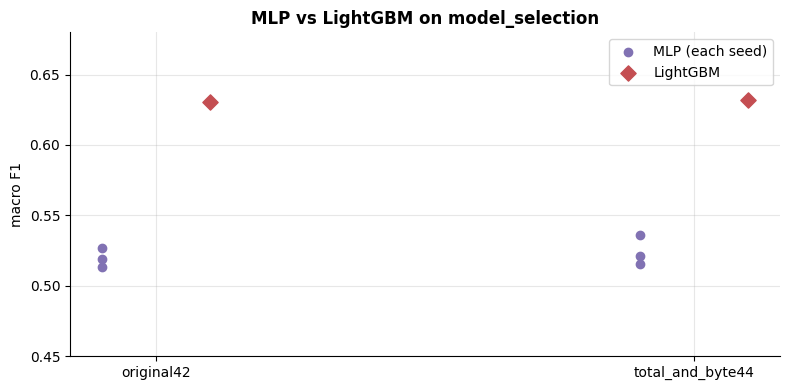

In [8]:
baseline = pd.read_csv(ROOT / 'results/tables/v3/06_results.csv')
lgbm = baseline[baseline.model == 'lightgbm'].set_index('feature set')
compare = pd.DataFrame({
    'MLP (mean of 3 seeds)': runs.groupby('feature set')['macro F1'].mean(),
    'LightGBM': lgbm['macro F1'],
    'MLP false-positive rate (mean)': runs.groupby('feature set')['false-positive rate'].mean(),
    'LightGBM false-positive rate': lgbm['false-positive rate'],
    'MLP Worms correct (each seed)': runs.groupby('feature set')['Worms correct (of 13)'].apply(list),
    'LightGBM Worms correct': lgbm['Worms correct (of 13)'],
})
save_table(compare, '07_mlp_vs_lightgbm', index=True)
display(compare)

fig, ax = plt.subplots(figsize=(8, 4))
for i, s in enumerate(SETS):
    vals = runs.loc[runs['feature set'] == s, 'macro F1']
    ax.scatter([i - 0.1] * 3, vals, color='#8172B3', zorder=3, label='MLP (each seed)' if i == 0 else None)
    ax.scatter(i + 0.1, lgbm.loc[s, 'macro F1'], color='#C44E52', marker='D', s=60, zorder=3, label='LightGBM' if i == 0 else None)
ax.set_xticks([0, 1], SETS); ax.set(ylabel='macro F1', ylim=(0.45, 0.68), title='MLP vs LightGBM on model_selection')
ax.legend(); plt.tight_layout(); save_figure(fig, '07_mlp_vs_lightgbm'); plt.show()

**What we see:**

- The MLP reaches a mean macro F1 of about **0.52**, clearly below LightGBM's **0.63**. Every MLP run is below LightGBM.
- Its accuracy (about 0.81) and attack recall (about 97%) are decent, so the gap is mostly in the **attack types**, not in spotting attacks.
- **All six MLP runs miss all 13 Worms rows**, while LightGBM finds 8 or 9.

## 7. Class by class: where does the MLP win and lose?

Correct predictions per class, MLP (seed 42) vs LightGBM, both on `total_and_byte44`.

In [9]:
lgbm_pred = pd.read_csv(DATA / '06_lightgbm_total_and_byte44_predictions.csv').predicted
lgbm_codes = pd.Categorical(lgbm_pred, categories=CLASSES).codes
mlp_codes = probabilities[('total_and_byte44', 42)].argmax(1)
by_class = pd.DataFrame({'rows': np.bincount(y_eval, minlength=10),
                         'MLP correct': [int(((y_eval == k) & (mlp_codes == k)).sum()) for k in range(10)],
                         'LightGBM correct': [int(((y_eval == k) & (lgbm_codes == k)).sum()) for k in range(10)]}, index=CLASSES)
by_class['difference (MLP - LightGBM)'] = by_class['MLP correct'] - by_class['LightGBM correct']
save_table(by_class, '07_correct_by_class', index=True)
display(by_class)

,rows,MLP correct,LightGBM correct,difference (MLP - LightGBM)
Analysis,200,21,30,-9
Backdoor,175,15,26,-11
DoS,1226,271,86,185
Exploits,3340,2942,3192,-250
Fuzzers,1818,1304,1391,-87
Generic,4000,3911,3923,-12
Normal,5600,4961,5127,-166
Reconnaissance,1049,763,779,-16
Shellcode,113,71,88,-17
Worms,13,0,9,-9


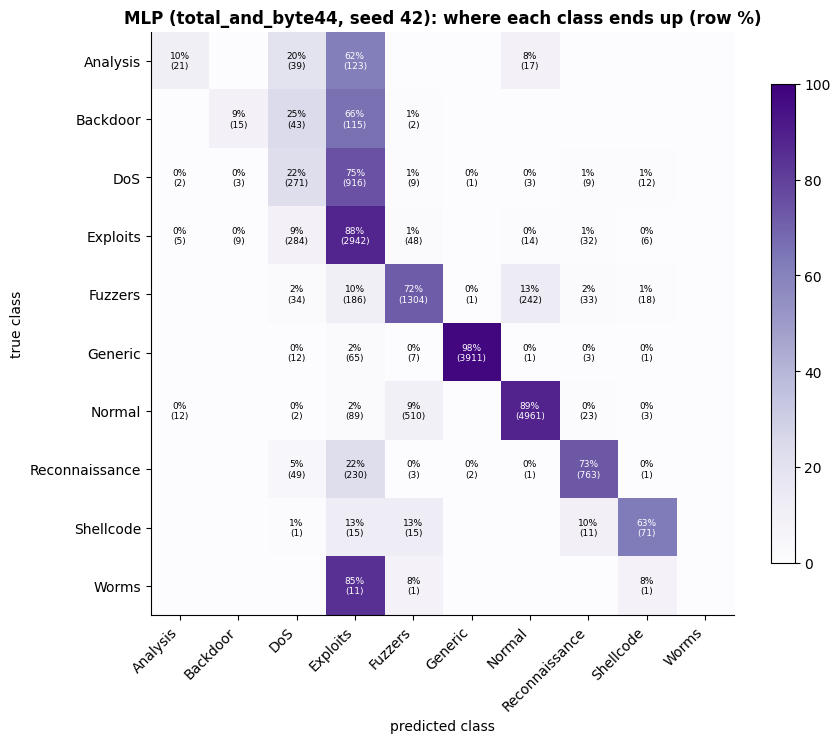

In [10]:
cm = confusion_matrix(y_eval, mlp_codes, labels=range(10))
cm_pct = cm / cm.sum(axis=1, keepdims=True) * 100
fig, ax = plt.subplots(figsize=(9, 7.5))
im = ax.imshow(cm_pct, cmap='Purples', vmin=0, vmax=100)
ax.set_xticks(range(10), CLASSES, rotation=45, ha='right'); ax.set_yticks(range(10), CLASSES); ax.grid(False)
for i in range(10):
    for j in range(10):
        if cm[i, j]:
            ax.text(j, i, f'{cm_pct[i, j]:.0f}%\n({cm[i, j]})', ha='center', va='center', fontsize=6.5,
                    color='white' if cm_pct[i, j] > 60 else 'black')
ax.set(xlabel='predicted class', ylabel='true class', title='MLP (total_and_byte44, seed 42): where each class ends up (row %)')
fig.colorbar(im, ax=ax, shrink=0.8); plt.tight_layout(); save_figure(fig, '07_mlp_confusion'); plt.show()

**What we see:**

- The MLP is much better on **DoS** (271 correct vs 86 for LightGBM), but worse on almost every other attack class,
  and it finds no Worms at all. Part of the DoS gain is bought with mistakes the other way: it labels 284 Exploits rows as DoS.
  A win on one class is not a win overall.
- Like LightGBM, it sends most Analysis and Backdoor rows to **Exploits**. These are the label conflicts from Notebook 02 again.

## 8. Do the engineered features help the MLP?

Same seed, same settings, only the feature set changes. Comparing seed by seed removes the effect of the random start.

In [11]:
paired = runs.pivot(index='seed', columns='feature set', values='macro F1')
paired['difference (44 - 42)'] = paired['total_and_byte44'] - paired['original42']
save_table(paired, '07_feature_effect_by_seed', index=True)
display(paired)

feature set,original42,total_and_byte44,difference (44 - 42)
seed,,,
42,0.5187,0.5360,0.0173
43,0.5272,0.5152,-0.0120
44,0.5134,0.5213,0.0078


**What we see:** the difference changes sign from seed to seed (two seeds up, one down). The average gain is less than half a point, smaller than the
seed-to-seed variation. **No reliable effect** of the engineered features on the MLP. This matches the tree models in Notebook 06.

## 9. Is PyTorch ready for the main model?

The main architecture (Conv1D and attention) will be built in **PyTorch**. An earlier attempt on this machine was blocked by Windows
(`WinError 4551`). We check with a tiny made-up example that PyTorch can now run a Conv1D layer forwards and backwards. No project data is used.

In [12]:
try:
    import torch
    layer = torch.nn.Conv1d(in_channels=1, out_channels=4, kernel_size=3)
    toy = torch.randn(2, 1, 10, requires_grad=True)
    layer(toy).sum().backward()
    print(f'PyTorch {torch.__version__}: Conv1D forward and backward OK on CPU (gradient shape {tuple(toy.grad.shape)})')
except Exception as error:   # report clearly instead of failing the notebook
    print('PyTorch is NOT usable here:', type(error).__name__, error)

PyTorch 2.14.0+cu130: Conv1D forward and backward OK on CPU (gradient shape (2, 1, 10))


## 10. Save

In [13]:
for (set_name, seed), model in fitted.items():
    joblib.dump(model, MODELS / f'07_mlp_{set_name}_seed{seed}.joblib')
    out = targets['model_selection'][['row_position', 'id', 'attack_cat']].copy()
    out['predicted'] = np.asarray(CLASSES)[probabilities[(set_name, seed)].argmax(1)]
    out['attack_score'] = 1 - probabilities[(set_name, seed)][:, NORMAL]
    for k, c in enumerate(CLASSES):
        out[f'p_{c}'] = probabilities[(set_name, seed)][:, k]
    out.to_csv(DATA / f'07_mlp_{set_name}_seed{seed}_predictions.csv', index=False)
pd.DataFrame({f'{s} seed {seed}': l for (s, seed), l in losses.items()}).to_csv(DATA / '07_training_losses.csv', index_label='epoch_minus_1')
save_json({'network': '128/64 ReLU, alpha 0.01, Adam lr 0.001, batch 512, 30 epochs', 'seeds': [42, 43, 44],
           'inputs': 'scaled versions of original42 and total_and_byte44', 'reference_baseline': 'LightGBM total_and_byte44, macro F1 0.632'},
          MODELS / '07_mlp_settings.json')
assert sha256(TRAIN_CSV) == RAW_SHA256['train']
leaderboard = []
for s in SETS:
    part = runs[runs['feature set'] == s]
    model = fitted[(s, 42)]
    leaderboard.append({'model': 'MLP (128/64)', 'feature set': s, 'runs': len(part),
                        'macro F1 mean': part['macro F1'].mean(), 'macro F1 std': part['macro F1'].std(),
                        'accuracy': part['accuracy'].mean(), 'attack recall': part['attack recall'].mean(),
                        'false-positive rate': part['false-positive rate'].mean(), 'attack avg precision': part['attack avg precision'].mean(),
                        'Worms correct (of 13)': part['Worms correct (of 13)'].mean(),
                        'parameters': sum(w.size for w in model.coefs_ + model.intercepts_),
                        'train minutes per run': np.mean([minutes[(s, seed)] for seed in [42, 43, 44]])})
write_leaderboard('07', leaderboard)
print('Saved 6 MLPs, their predictions, training losses and leaderboard rows. Calibration rows and the test file were not used.')

Saved 6 MLPs, their predictions, training losses and leaderboard rows. Calibration rows and the test file were not used.


## Summary

### What we learned

| Question | Answer |
|---|---|
| How good is a plain neural network? | Mean macro F1 **0.520** (original42) and **0.524** (total_and_byte44) over 3 seeds |
| Compared with LightGBM? | Clearly worse: LightGBM reaches **0.631 / 0.632** on the same rows |
| Where does it differ? | Much better on DoS, worse on most other attacks, and **0 of 13 Worms** in every run |
| Engineered features? | No reliable effect; the sign changes between seeds |
| Ready for deep learning? | Yes: PyTorch runs Conv1D on this machine's CPU |

### What is still uncertain

- A longer-trained or larger MLP might do somewhat better. Only two settings and 30 epochs were tried.
- Worms has only 13 evaluation rows, so rare-class results stay shaky.

### What comes next: the main model

**Notebook 08** starts the main implementation: a **Conv1D + attention** network adapted to our one-row-per-flow data, in PyTorch.
It must beat both reference points from these notebooks:

- the **MLP** (about 0.52), to show that convolution and attention add something beyond a plain network, and
- **LightGBM** (about 0.63), the strongest model so far.

Note: our data has no DNS-query records and no timestamps (Notebook 01), so this will be a **tabular adaptation** of the paper's architecture,
and we will say so clearly.